# Experiment 03 — behaviour cloning visualisation

Two artefacts:

1. `results/training_log.json` — per-epoch MSE training loss.
2. `results/can_ph.json` — closed-loop evaluation grid.

Headline: **4 / 60 = 0.067** closed-loop success on `can/ph`, from a 290k-parameter MLP trained for 500 epochs.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

train = json.loads(Path('results/training_log.json').read_text())
evalr = json.loads(Path('results/can_ph.json').read_text())

print(f"hidden: {train['hidden_sizes']}, params: {train['n_params']:,}")
print(f"epochs: {train['epochs']}, batch: {train['batch_size']}, lr: {train['learning_rate']}")
print(f"n_transitions: {train['n_transitions']}, obs_dim: {train['obs_dim']}, action_dim: {train['action_dim']}")
print(f"final_loss: {train['final_loss']:.6f}")
print(f"eval success: {evalr['n_success']}/{evalr['n_total']} "
      f"= {evalr['success_rate']:.3f}")

hidden: [512, 512], params: 290,311
epochs: 500, batch: 256, lr: 0.0001
n_transitions: 23207, obs_dim: 46, action_dim: 7
final_loss: 0.006021
eval success: 4/60 = 0.067


## Training loss curve (log scale)

Standard MSE training on `(obs, action)` pairs. The curve is smooth and monotone — no obvious optimisation issues. The interesting question is *not* whether the loss is low (it is) but whether low MSE on demo transitions correlates with closed-loop success (it does not, very much; that's the BC compounding error story).

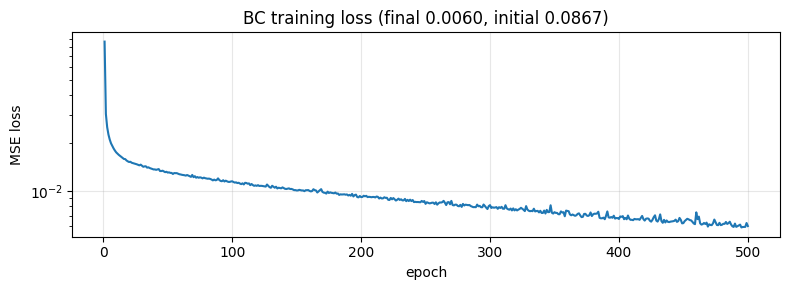

In [2]:
losses = np.array([e['loss'] for e in train['per_epoch']])
epochs = np.array([e['epoch'] for e in train['per_epoch']])

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(epochs, losses, color='tab:blue')
ax.set_xlabel('epoch')
ax.set_ylabel('MSE loss')
ax.set_yscale('log')
ax.set_title(f'BC training loss (final {losses[-1]:.4f}, initial {losses[0]:.4f})')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Closed-loop success grid (20 init-states × 3 rollouts)

Same 20 init-states as exp 01 / exp 02, with 3 stochastic-tie-broken closed-loop rollouts each. The grid is mostly red — only 4 cells are green.

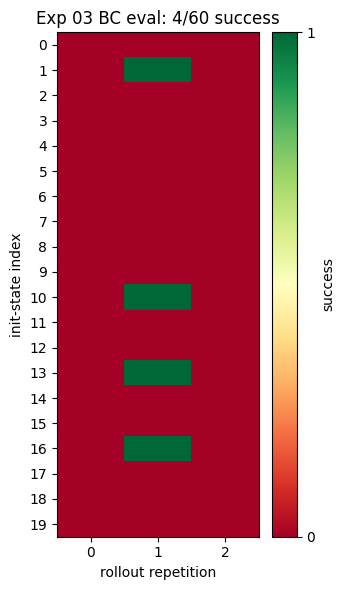

In [3]:
n_demos = evalr['n_demos_attempted']
n_rollouts = evalr['n_rollouts_per_demo']
grid = np.zeros((n_demos, n_rollouts), dtype=int)
for r in evalr['per_rollout']:
    di = int(r['demo'].replace('demo_', ''))
    grid[di, r['rollout_idx']] = int(r['success'])

fig, ax = plt.subplots(figsize=(3.5, 6))
im = ax.imshow(grid, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(n_rollouts))
ax.set_yticks(range(n_demos))
ax.set_xlabel('rollout repetition')
ax.set_ylabel('init-state index')
ax.set_title(f'Exp 03 BC eval: {int(grid.sum())}/{grid.size} success')
plt.colorbar(im, ax=ax, label='success', ticks=[0, 1])
plt.tight_layout()
plt.show()

## Per init-state success rate (collapse over the 3 rollouts)

Most init-states are 0/3; the ones that succeed are mostly 1/3, consistent with stochastic tie-breaking on a borderline-capable policy.

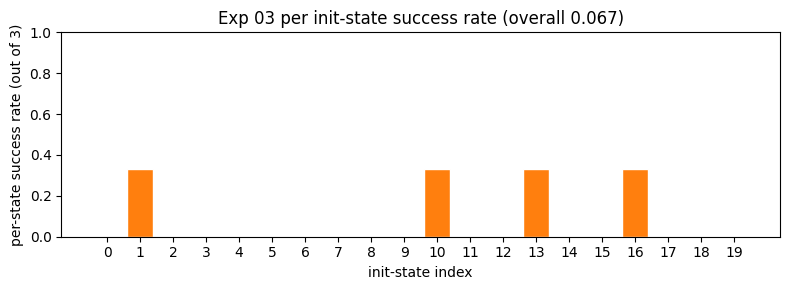

In [4]:
per_demo_rate = grid.mean(axis=1)
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(range(n_demos), per_demo_rate, color='tab:orange', edgecolor='white')
ax.set_xlabel('init-state index')
ax.set_ylabel('per-state success rate (out of 3)')
ax.set_title(f'Exp 03 per init-state success rate (overall {per_demo_rate.mean():.3f})')
ax.set_xticks(range(n_demos))
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

## Takeaway

Training loss drops cleanly to ~1e-2 MSE; closed-loop success stays at 6.7%. This is the canonical BC story: the policy can match the demo distribution on demo states, but small early errors put the rollout in states the demo never visited, where the MSE-trained MLP has no calibrated response. The whole point of exp 05 (hybrid prior + MBD correction) is to add an online model-based score that pulls the rollout back toward task-success regions even when the prior alone wanders off.